# Milestone 1: Formula 1 Podium Prediction Companion

**Task:** For each driver entering a race, predict whether they finish on the podium
(`positionOrder <= 3`) using only information known **after qualifying / when the grid
is fixed and before the race starts**.

**Primary metric:** PR-AUC (podiums are rare ≈ 15% in the modern era).
**Secondary:** F1 (threshold tuned on validation only) and ROC-AUC.

**Split:** time-based — Train `year <= 2019`, Validation `2020–2021`, Test `year >= 2022`.

In [52]:
# --- Setup ---
%matplotlib inline
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
# Ensure figures are captured in notebook outputs under nbconvert / Agg
matplotlib.rcParams['figure.max_open_warning'] = 50
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_recall_curve, roc_curve, classification_report,
    confusion_matrix
)
from sklearn.inspection import permutation_importance

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

# Paths: Kaggle first, then local ./data
CANDIDATES = [
    Path('/kaggle/input/formula-1-world-championship-1950-2020'),
    Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'),
    Path('data'),
]
DATA_DIR = next((p for p in CANDIDATES if p.exists()), Path('data'))
print('DATA_DIR =', DATA_DIR.resolve())
assert DATA_DIR.exists(), 'Dataset folder not found'

DATA_DIR = /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


## 1. Load & Inspect Tables

The Ergast / Kaggle dump is **relational**: 14 CSVs linked by IDs. Our unit of analysis
is one row per `(raceId, driverId)` from `results`, enriched with races, drivers,
constructors, circuits, qualifying, and pre-race standings.

In [53]:
TABLES = [
    'circuits', 'constructors', 'constructor_results', 'constructor_standings',
    'drivers', 'driver_standings', 'races', 'results', 'qualifying',
    'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status'
]

raw = {}
for name in TABLES:
    path = DATA_DIR / f'{name}.csv'
    # Ergast sentinel for missing is the literal string \N
    raw[name] = pd.read_csv(path, na_values=['\\N'])
    print(f'{name:25s} shape={raw[name].shape}')

# Working copies — raw CSVs stay immutable
circuits = raw['circuits'].copy()
constructors = raw['constructors'].copy()
drivers = raw['drivers'].copy()
races = raw['races'].copy()
results = raw['results'].copy()
qualifying = raw['qualifying'].copy()
driver_standings = raw['driver_standings'].copy()
constructor_standings = raw['constructor_standings'].copy()
status = raw['status'].copy()
sprint_results = raw['sprint_results'].copy()

results.head()

circuits                  shape=(77, 9)
constructors              shape=(212, 5)
constructor_results       shape=(12625, 5)
constructor_standings     shape=(13391, 7)
drivers                   shape=(861, 9)
driver_standings          shape=(34863, 7)
races                     shape=(1125, 18)
results                   shape=(26759, 18)
qualifying                shape=(10494, 9)
lap_times                 shape=(589081, 6)
pit_stops                 shape=(11371, 7)
sprint_results            shape=(360, 16)
seasons                   shape=(75, 2)
status                    shape=(139, 2)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [54]:
# Structure overview (info / describe / nulls)
print('=== results.info ===')
results.info()
print('\n=== Null counts (results) ===')
print(results.isnull().sum().sort_values(ascending=False).head(15))
print('\n=== Numeric summary ===')
results.describe().T.head(12)

=== results.info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   floa

,count,mean,std,min,25%,50%,75%,max
resultId,26759.0,1.338098e+04,7.726135e+03,1.0,6690.5,13380.0,20069.5,26764.0
raceId,26759.0,5.516873e+02,3.132650e+02,1.0,300.0,531.0,811.0,1144.0
driverId,26759.0,2.786735e+02,2.827030e+02,1.0,57.0,172.0,399.5,862.0
constructorId,26759.0,5.018054e+01,6.155150e+01,1.0,6.0,25.0,63.0,215.0
number,26753.0,1.815393e+01,1.558113e+01,0.0,7.0,16.0,24.0,208.0
grid,26759.0,1.113480e+01,7.202860e+00,0.0,5.0,11.0,17.0,34.0
position,15806.0,8.020499e+00,4.840796e+00,1.0,4.0,8.0,11.0,33.0
positionOrder,26759.0,1.279405e+01,7.665951e+00,1.0,6.0,12.0,18.0,39.0
points,26759.0,1.987632e+00,4.351209e+00,0.0,0.0,0.0,2.0,50.0
laps,26759.0,4.630177e+01,2.949656e+01,0.0,23.0,53.0,66.0,200.0


## 2. Cleaning & Auditing

### 2.1 Semantic typing

Convert race dates to datetimes and qualifying lap-time strings (`M:SS.mmm`) to seconds.

In [55]:
def lap_time_to_seconds(x):
    '''Parse Ergast lap/qualifying times like 1:26.572 into float seconds.'''
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s in ('', 'nan', 'None'):
        return np.nan
    try:
        parts = s.split(':')
        if len(parts) == 2:
            return float(parts[0]) * 60 + float(parts[1])
        if len(parts) == 3:
            return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])
        return float(s)
    except Exception:
        return np.nan

races['date'] = pd.to_datetime(races['date'], errors='coerce')
drivers['dob'] = pd.to_datetime(drivers['dob'], errors='coerce')

for col in ['q1', 'q2', 'q3']:
    qualifying[f'{col}_sec'] = qualifying[col].map(lap_time_to_seconds)

# Best qualifying lap in seconds (min of available Q sessions)
qualifying['best_quali_sec'] = qualifying[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)

print('Qualifying coverage by parsed seconds:')
print(qualifying[['q1_sec', 'q2_sec', 'q3_sec', 'best_quali_sec']].notna().mean())
qualifying[['q1', 'q1_sec', 'best_quali_sec']].head()

Qualifying coverage by parsed seconds:
q1_sec            0.985134
q2_sec            0.557176
q3_sec            0.345817
best_quali_sec    0.985134
dtype: float64


,q1,q1_sec,best_quali_sec
0,1:26.572,86.572,85.187
1,1:26.103,86.103,85.315
2,1:25.664,85.664,85.452
3,1:25.994,85.994,85.691
4,1:25.960,85.960,85.518


### 2.2 Grain: one row per `(raceId, driverId)`

Early F1 allowed **shared drives** (same driver appears twice in one race). The modeling
table must be unique on `(raceId, driverId)`.

**Rule chosen:** keep the row with the **best (lowest) `positionOrder`**. Rationale: that
row reflects the driver's most competitive outcome in that race and avoids keeping a
mid-race swap that never finished. We also drop Indianapolis 500 championship rounds
(1950–1960) because almost no F1 regulars entered and they distort home-race analysis.

In [56]:
n_before = len(results)
n_dup_pairs = results.duplicated(['raceId', 'driverId']).sum()
print(f'Results rows before: {n_before}, duplicate (raceId,driverId) extras: {n_dup_pairs}')

results_clean = (
    results.sort_values(['raceId', 'driverId', 'positionOrder'])
           .drop_duplicates(['raceId', 'driverId'], keep='first')
           .copy()
)
print(f'Results rows after grain fix: {len(results_clean)} (removed {n_before - len(results_clean)})')
assert results_clean.duplicated(['raceId', 'driverId']).sum() == 0

# Exclude Indianapolis 500 (circuitId often 19 in Ergast; also match by name)
indy_races = races[races['name'].str.contains('Indianapolis', case=False, na=False)]['raceId']
print(f'Indianapolis races excluded: {len(indy_races)}')
results_clean = results_clean[~results_clean['raceId'].isin(indy_races)].copy()
print(f'Results after Indy exclusion: {len(results_clean)}')

# Target label (post-race — used ONLY as y, never as a feature)
results_clean['podium'] = (results_clean['positionOrder'] <= 3).astype(int)
print('Overall podium rate: {:.3f}'.format(results_clean['podium'].mean()))

Results rows before: 26759, duplicate (raceId,driverId) extras: 91
Results rows after grain fix: 26668 (removed 91)
Indianapolis races excluded: 11
Results after Indy exclusion: 26287
Overall podium rate: 0.128


### 2.3 Primary-key / foreign-key audit

Raw files are immutable; we audit copies. Every foreign key must exist in its parent table.

In [57]:
def audit_pk(df, cols, name):
    ok_unique = df.duplicated(cols).sum() == 0
    ok_nonnull = df[cols].notna().all().all()
    print(f'PK {name} {cols}: unique={ok_unique}, non-null={ok_nonnull}')
    return ok_unique and ok_nonnull

def audit_fk(child, col, parent, pcol, label):
    missing = ~child[col].dropna().isin(parent[pcol])
    n = int(missing.sum())
    print(f'FK {label}: orphan values = {n}')
    return n == 0

audit_pk(races, ['raceId'], 'races')
audit_pk(drivers, ['driverId'], 'drivers')
audit_pk(constructors, ['constructorId'], 'constructors')
audit_pk(circuits, ['circuitId'], 'circuits')
audit_pk(status, ['statusId'], 'status')
audit_pk(results_clean, ['resultId'], 'results_clean')

audit_fk(results_clean, 'raceId', races, 'raceId', 'results.raceId -> races')
audit_fk(results_clean, 'driverId', drivers, 'driverId', 'results.driverId -> drivers')
audit_fk(results_clean, 'constructorId', constructors, 'constructorId', 'results.constructorId -> constructors')
audit_fk(results_clean, 'statusId', status, 'statusId', 'results.statusId -> status')
audit_fk(races, 'circuitId', circuits, 'circuitId', 'races.circuitId -> circuits')
audit_fk(qualifying, 'raceId', races, 'raceId', 'qualifying.raceId -> races')

PK races ['raceId']: unique=True, non-null=True
PK drivers ['driverId']: unique=True, non-null=True
PK constructors ['constructorId']: unique=True, non-null=True
PK circuits ['circuitId']: unique=True, non-null=True
PK status ['statusId']: unique=True, non-null=True
PK results_clean ['resultId']: unique=True, non-null=True
FK results.raceId -> races: orphan values = 0
FK results.driverId -> drivers: orphan values = 0
FK results.constructorId -> constructors: orphan values = 0
FK results.statusId -> status: orphan values = 0
FK races.circuitId -> circuits: orphan values = 0
FK qualifying.raceId -> races: orphan values = 0


True

## 3. Exploratory Data Analysis (before & after cleaning)

EDA must be plot-backed. We look at class imbalance, qualifying coverage drift,
grid vs qualifying mismatch, and cleaning impact.

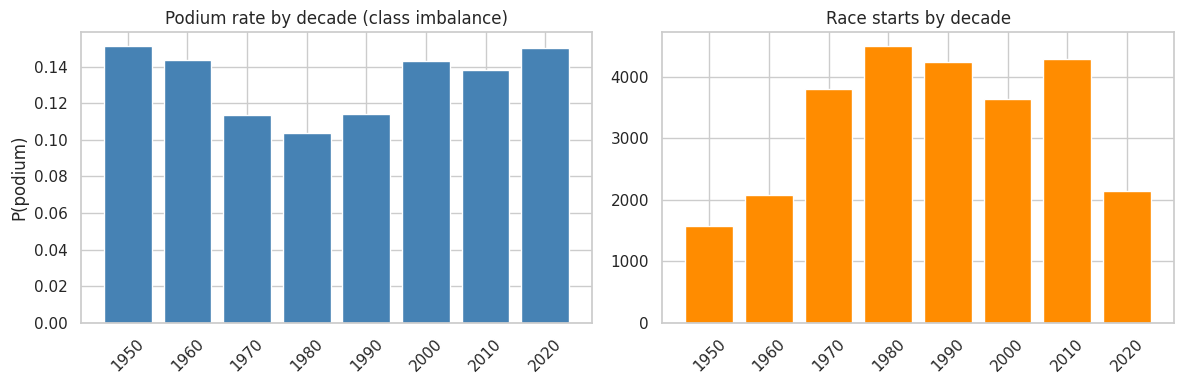

decade
1950    0.151207
1960    0.143614
1970    0.113505
1980    0.103931
1990    0.114353
2000    0.143288
2010    0.138236
2020    0.150070
Name: podium, dtype: float64


In [58]:
# Attach year for EDA
eda = results_clean.merge(races[['raceId', 'year', 'circuitId', 'name', 'date', 'round']],
                          on='raceId', how='left')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eda['decade'] = (eda['year'] // 10) * 10
pod_by_decade = eda.groupby('decade')['podium'].mean()
axes[0].bar(pod_by_decade.index.astype(str), pod_by_decade.values, color='steelblue')
axes[0].set_title('Podium rate by decade (class imbalance)')
axes[0].set_ylabel('P(podium)')
axes[0].tick_params(axis='x', rotation=45)

starts = eda.groupby('decade').size()
axes[1].bar(starts.index.astype(str), starts.values, color='darkorange')
axes[1].set_title('Race starts by decade')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
print(pod_by_decade)

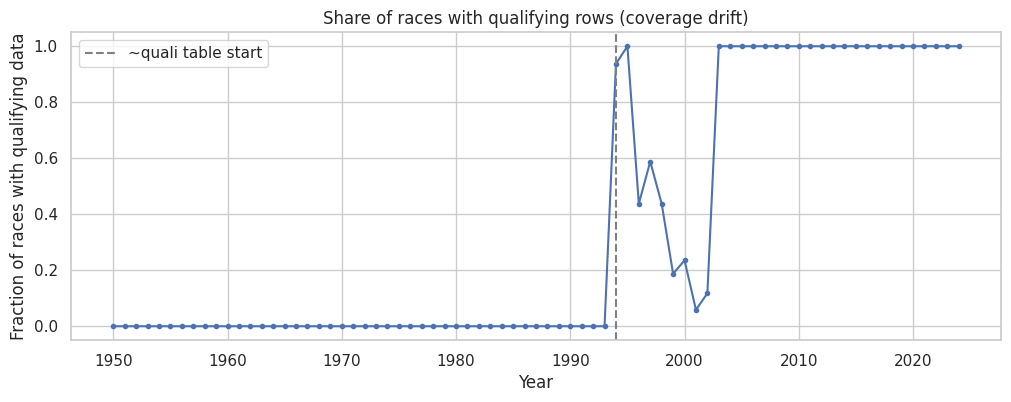

year
1990    0.000000
1991    0.000000
1992    0.000000
1993    0.000000
1994    0.937500
1995    1.000000
1996    0.437500
1997    0.588235
1998    0.437500
1999    0.187500
2000    0.235294
2001    0.058824
2002    0.117647
2003    1.000000
2004    1.000000
Name: has_quali, dtype: float64


In [59]:
# Qualifying coverage drift — why we cannot blindly rely on quali features pre-2000s
quali_races = qualifying.groupby('raceId').size().rename('n_quali')
race_cov = races[['raceId', 'year']].merge(quali_races, on='raceId', how='left')
race_cov['has_quali'] = race_cov['n_quali'].fillna(0) > 0
cov_by_year = race_cov.groupby('year')['has_quali'].mean()

plt.figure(figsize=(12, 4))
plt.plot(cov_by_year.index, cov_by_year.values, marker='o', markersize=3)
plt.title('Share of races with qualifying rows (coverage drift)')
plt.ylabel('Fraction of races with qualifying data')
plt.xlabel('Year')
plt.ylim(-0.05, 1.05)
plt.axvline(1994, color='gray', ls='--', label='~quali table start')
plt.legend()
plt.show()
print(cov_by_year.loc[cov_by_year.index >= 1990].head(15))

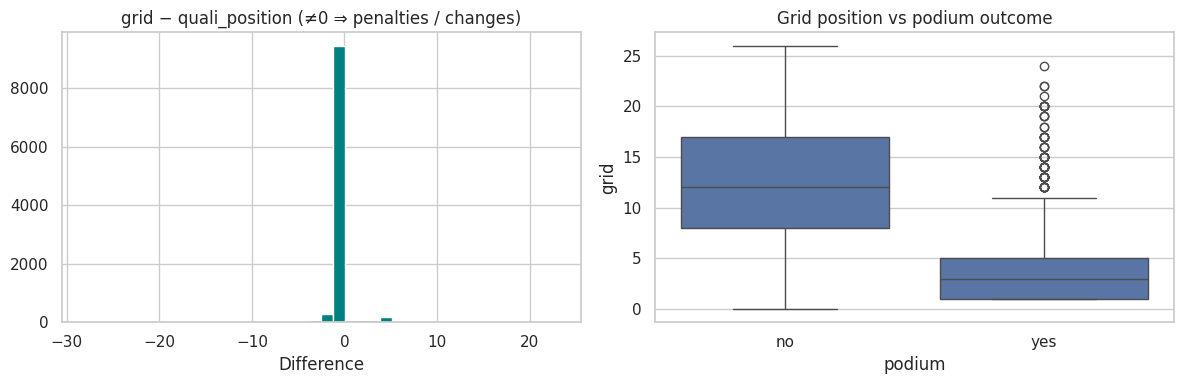

Share of rows where grid != quali_position: 0.239
Grid==0 (pit-lane / DNS coding) count in modeling candidates: 1635


In [60]:
# Grid vs qualifying position (penalties make them differ)
qpos = qualifying.rename(columns={'position': 'quali_position'})[
    ['raceId', 'driverId', 'quali_position', 'best_quali_sec']
]
cmp_ = eda.merge(qpos, on=['raceId', 'driverId'], how='inner')
cmp_['grid_minus_quali'] = cmp_['grid'] - cmp_['quali_position']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(cmp_['grid_minus_quali'].dropna(), bins=40, color='teal')
axes[0].set_title('grid − quali_position (≠0 ⇒ penalties / changes)')
axes[0].set_xlabel('Difference')

sns.boxplot(data=cmp_.assign(podium=cmp_['podium'].map({0: 'no', 1: 'yes'})),
            x='podium', y='grid', ax=axes[1])
axes[1].set_title('Grid position vs podium outcome')
plt.tight_layout()
plt.show()
print('Share of rows where grid != quali_position: {:.3f}'.format(
    (cmp_['grid'] != cmp_['quali_position']).mean()))
print('Grid==0 (pit-lane / DNS coding) count in modeling candidates:', (eda['grid'] == 0).sum())

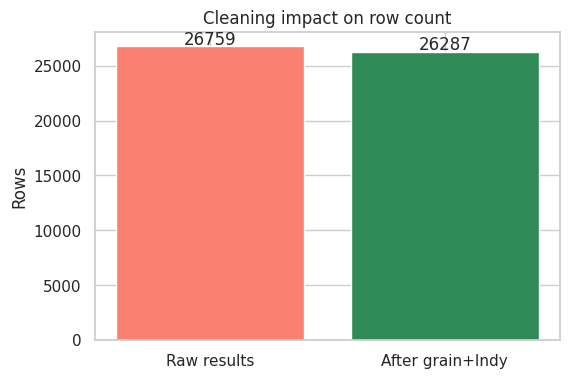

Removed 472 rows (1.76%)


In [61]:
# Cleaning impact: duplicate removal + Indy exclusion vs raw results
raw_n = len(raw['results'])
clean_n = len(results_clean)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Raw results', 'After grain+Indy'], [raw_n, clean_n], color=['salmon', 'seagreen'])
ax.set_ylabel('Rows')
ax.set_title('Cleaning impact on row count')
for i, v in enumerate([raw_n, clean_n]):
    ax.text(i, v + 200, str(v), ha='center')
plt.show()
print(f'Removed {raw_n - clean_n} rows ({100*(raw_n-clean_n)/raw_n:.2f}%)')

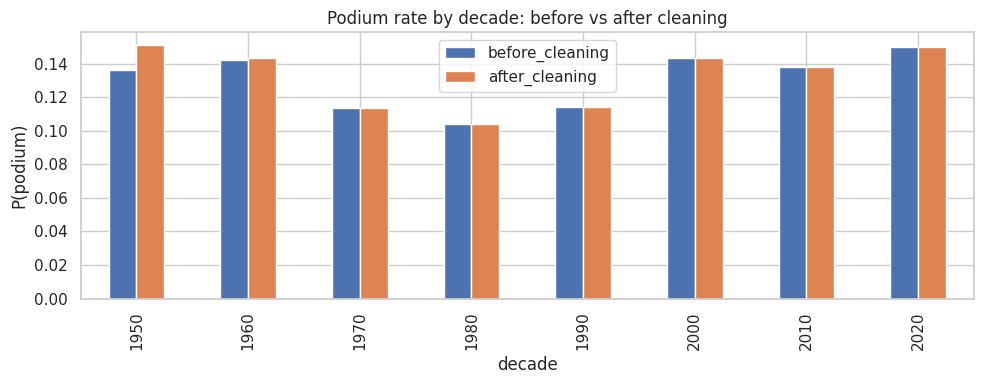

,before_cleaning,after_cleaning
decade,,
1950,0.136024,0.151207
1960,0.142451,0.143614
1970,0.113475,0.113505
1980,0.103931,0.103931
1990,0.114353,0.114353
2000,0.143288,0.143288
2010,0.138236,0.138236
2020,0.150070,0.150070


In [62]:
# EDA before vs after cleaning: podium rate by decade
raw_eda = raw['results'].copy()
raw_eda['podium'] = (raw_eda['positionOrder'] <= 3).astype(int)
raw_eda = raw_eda.merge(races[['raceId', 'year']], on='raceId', how='left')
raw_eda['decade'] = (raw_eda['year'] // 10) * 10
before = raw_eda.groupby('decade')['podium'].mean()
after = eda.groupby('decade')['podium'].mean()
cmp_ba = pd.DataFrame({'before_cleaning': before, 'after_cleaning': after})
cmp_ba.plot(kind='bar', figsize=(10, 4))
plt.title('Podium rate by decade: before vs after cleaning')
plt.ylabel('P(podium)')
plt.tight_layout()
plt.show()
display(cmp_ba)


## 4. Data-Engineering Questions

Each answer uses **multi-hop joins**, a plot, and notes on grain / missingness / cutoff.

### Q1 — Which circuits convert a front-row start into a podium most often?
Distinguish **qualifying position** from **grid**. Compare pre-2014 vs hybrid era (≥2014).

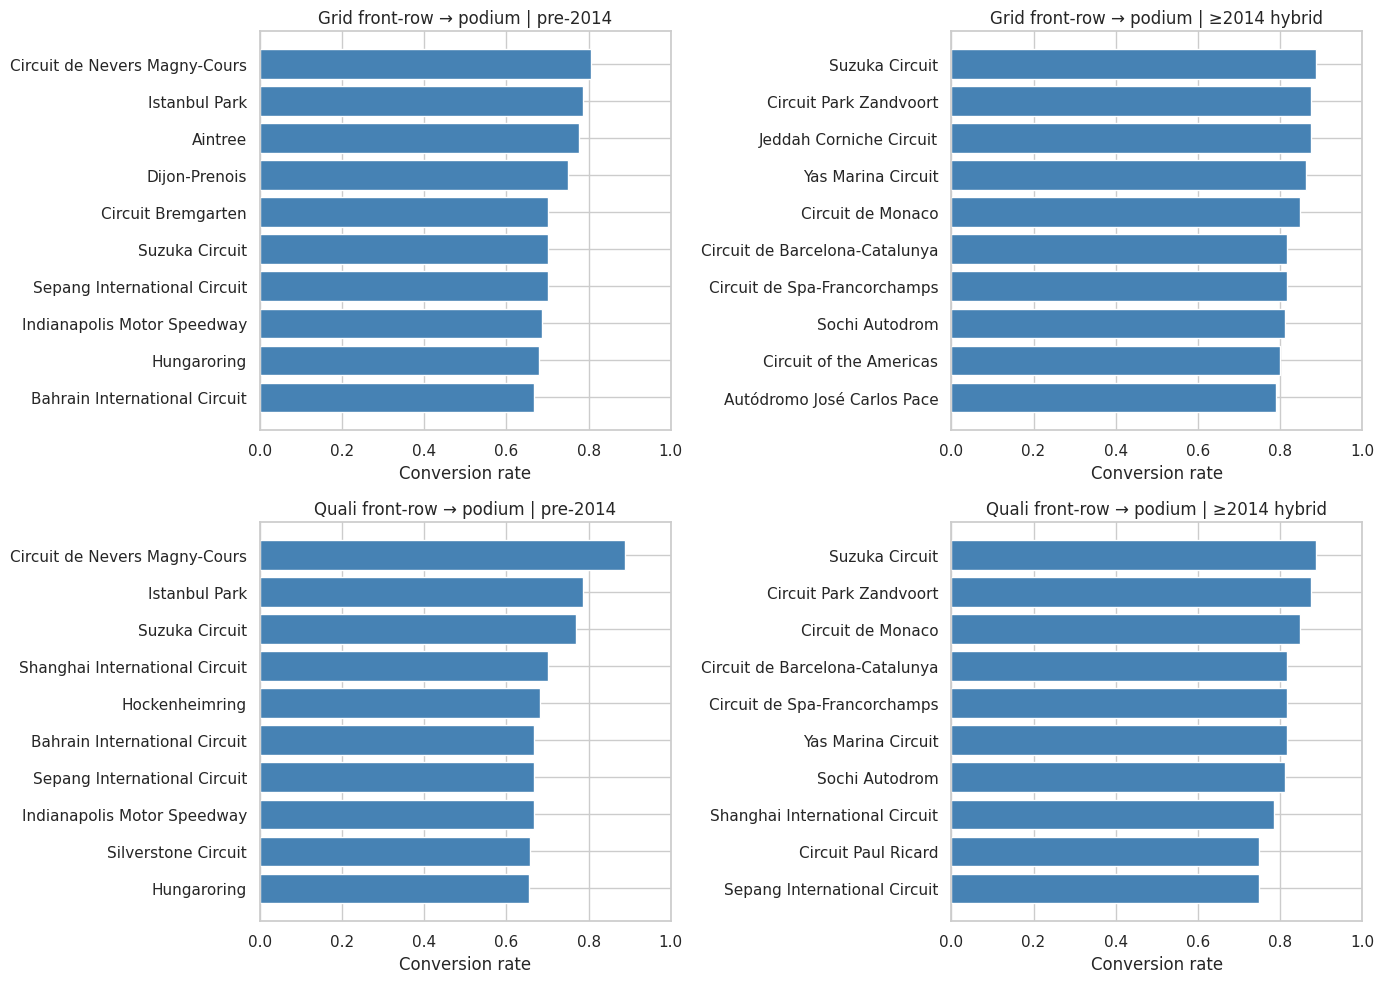

Top circuits (grid, ≥2014):


,starts,podiums,rate
name,,,
Suzuka Circuit,18,16,0.888889
Circuit Park Zandvoort,8,7,0.875000
Jeddah Corniche Circuit,8,7,0.875000
Yas Marina Circuit,22,19,0.863636
Circuit de Monaco,20,17,0.850000
Circuit de Barcelona-Catalunya,22,18,0.818182
Circuit de Spa-Francorchamps,22,18,0.818182
Sochi Autodrom,16,13,0.812500



Note: grain = driver-race starts on front row; missing quali before ~1990s reduces quali-based ranks.
Cutoff: grid/quali are pre-race; podium label is post-race (analysis only).


In [63]:
# Join results → races → circuits; attach quali position
q1 = (
    results_clean[['raceId', 'driverId', 'grid', 'positionOrder', 'podium']]
    .merge(races[['raceId', 'year', 'circuitId']], on='raceId')
    .merge(circuits[['circuitId', 'name', 'country']], on='circuitId')
    .merge(qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_position'}),
           on=['raceId', 'driverId'], how='left')
)

def front_row_conversion(df, pos_col, era_mask, min_starts=8):
    sub = df[era_mask & df[pos_col].isin([1, 2])]
    g = sub.groupby('name').agg(starts=(pos_col, 'size'), podiums=('podium', 'sum'))
    g['rate'] = g['podiums'] / g['starts']
    return g[g['starts'] >= min_starts].sort_values('rate', ascending=False)

pre = front_row_conversion(q1, 'grid', q1['year'] < 2014)
post = front_row_conversion(q1, 'grid', q1['year'] >= 2014)
pre_q = front_row_conversion(q1, 'quali_position', q1['year'] < 2014)
post_q = front_row_conversion(q1, 'quali_position', q1['year'] >= 2014)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, table, title in [
    (axes[0, 0], pre.head(10), 'Grid front-row → podium | pre-2014'),
    (axes[0, 1], post.head(10), 'Grid front-row → podium | ≥2014 hybrid'),
    (axes[1, 0], pre_q.head(10), 'Quali front-row → podium | pre-2014'),
    (axes[1, 1], post_q.head(10), 'Quali front-row → podium | ≥2014 hybrid'),
]:
    ax.barh(table.index[::-1], table['rate'][::-1], color='steelblue')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Conversion rate')
    ax.set_title(title)
plt.tight_layout()
plt.show()

print('Top circuits (grid, ≥2014):')
display(post.head(8))
print('\nNote: grain = driver-race starts on front row; missing quali before ~1990s reduces quali-based ranks.')
print('Cutoff: grid/quali are pre-race; podium label is post-race (analysis only).')

**Q1 answer.** Front-row conversion is high, and the circuit ranking changes after 2014. Grain is one cleaned driver–race; a front row is grid or qualifying position in {1, 2}, with at least 8 such starts. Grid is nearly complete; qualifying is missing for most pre-1990s races, so the qualifying ranking is a smaller, later sample. Both are pre-race information; the podium is the outcome, not a feature.

On the grid definition for 2014 onward, the highest rates are Suzuka (0.889, 18 starts), Zandvoort (0.875, 8), Jeddah (0.875, 8), Yas Marina (0.864, 22), and Monaco (0.850, 20). Zandvoort and Jeddah are thin samples. The pre-2014 panel is led by different circuits (Nevers Magny-Cours, Istanbul Park, Aintree, Dijon-Prenois). The qualifying panels are close to the grid panels but not the same, which is what penalties should do.


### Q2 — Home-country podium advantage controlling for starting grid

Compare home vs away **within the same grid bin** so the effect is not just “home drivers qualify better.”

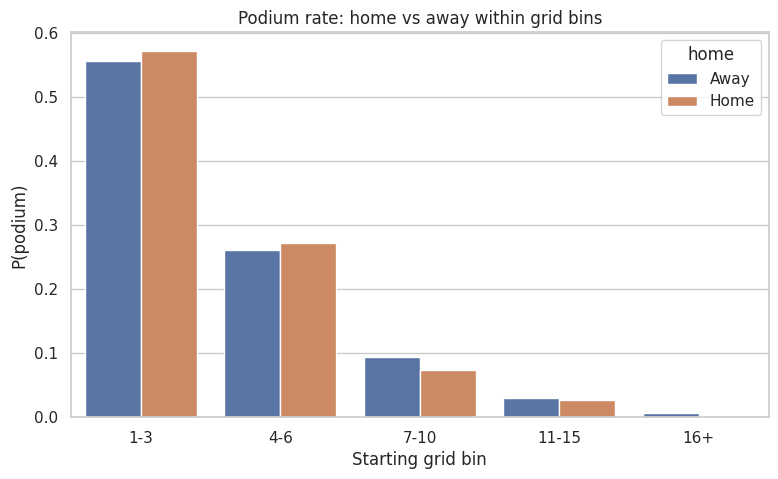

home,Away,Home
grid_bin,,
1-3,0.555377,0.572052
4-6,0.261261,0.271111
7-10,0.093356,0.074184
11-15,0.029984,0.026570
16+,0.007324,0.002714


Unmapped nationalities: nationality
Chilean            37
Rhodesian          18
Liechtensteiner    13
Indonesian         12
Argentinian         9
Name: count, dtype: int64
Grain: one driver-race; home requires nationality↔country map; Indy already excluded.


In [64]:
# Map driver nationality → circuit country (document the mapping)
NAT_TO_COUNTRY = {
    'British': 'UK', 'German': 'Germany', 'East German': 'Germany',
    'French': 'France', 'Italian': 'Italy', 'Spanish': 'Spain',
    'Brazilian': 'Brazil', 'Australian': 'Australia', 'Finnish': 'Finland',
    'Dutch': 'Netherlands', 'Mexican': 'Mexico', 'Canadian': 'Canada',
    'American': 'USA', 'Japanese': 'Japan', 'Austrian': 'Austria',
    'Swiss': 'Switzerland', 'Belgian': 'Belgium', 'Danish': 'Denmark',
    'Swedish': 'Sweden', 'Polish': 'Poland', 'Russian': 'Russia',
    'Chinese': 'China', 'Thai': 'Thailand', 'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand', 'Argentine': 'Argentina',
    'Colombian': 'Colombia', 'Venezuelan': 'Venezuela', 'Indian': 'India',
    'Portuguese': 'Portugal', 'Hungarian': 'Hungary', 'Irish': 'Ireland',
    'South African': 'South Africa', 'Malaysian': 'Malaysia',
}

# Normalize circuit country labels
country_norm = circuits[['circuitId', 'country']].copy()
country_norm['country_std'] = country_norm['country'].replace({
    'United States': 'USA', 'USA': 'USA', 'UK': 'UK', 'United Kingdom': 'UK'
})

q2 = (
    results_clean[['raceId', 'driverId', 'grid', 'podium']]
    .merge(races[['raceId', 'circuitId', 'year']], on='raceId')
    .merge(country_norm, on='circuitId')
    .merge(drivers[['driverId', 'nationality']], on='driverId')
)
q2['driver_country'] = q2['nationality'].map(NAT_TO_COUNTRY)
q2['is_home'] = (q2['driver_country'] == q2['country_std']).astype(int)
# Grid bins to control for starting position
q2['grid_bin'] = pd.cut(
    q2['grid'].replace(0, np.nan),
    bins=[0, 3, 6, 10, 15, 40],
    labels=['1-3', '4-6', '7-10', '11-15', '16+']
)

ctrl = (
    q2.dropna(subset=['grid_bin'])
      .groupby(['grid_bin', 'is_home'], observed=True)
      .agg(n=('podium', 'size'), rate=('podium', 'mean'))
      .reset_index()
)
ctrl['home'] = ctrl['is_home'].map({0: 'Away', 1: 'Home'})

plt.figure(figsize=(9, 5))
sns.barplot(data=ctrl, x='grid_bin', y='rate', hue='home')
plt.title('Podium rate: home vs away within grid bins')
plt.ylabel('P(podium)')
plt.xlabel('Starting grid bin')
plt.show()
display(ctrl.pivot(index='grid_bin', columns='home', values='rate'))
print('Unmapped nationalities:', q2.loc[q2['driver_country'].isna(), 'nationality'].value_counts().head())
print('Grain: one driver-race; home requires nationality↔country map; Indy already excluded.')

**Q2 answer.** After controlling for grid, a home circuit is only a small advantage, and only near the front. Home means the nationality-to-country map matches the circuit (British to UK, American to USA, and so on). Unmapped nationalities never count as home. Grid 0 is left out of the bins.

Within bins the podium rates are: grid 1–3, away 0.555 vs home 0.572; grid 4–6, 0.261 vs 0.271; grid 7–10, 0.093 vs 0.074; grid 11–15, 0.030 vs 0.027; grid 16+, 0.007 vs 0.003. Starting position dominates. This is an association, not evidence that racing at home causes a podium.


### Q3 — Constructor mechanical-retirement rates: 2014–2021 vs 2022–2024

Mechanical = component failure (engine, gearbox, …), **not** crash / driver / regulation.
Status is post-race — valid for this analysis question, **forbidden as a modeling feature**.

Mechanical status count: 73 / 139
['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension', 'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Tyre', 'Puncture', 'Driveshaft', 'Fuel pressure', 'Front wing', 'Water pressure', 'Wheel', 'Throttle'] ...


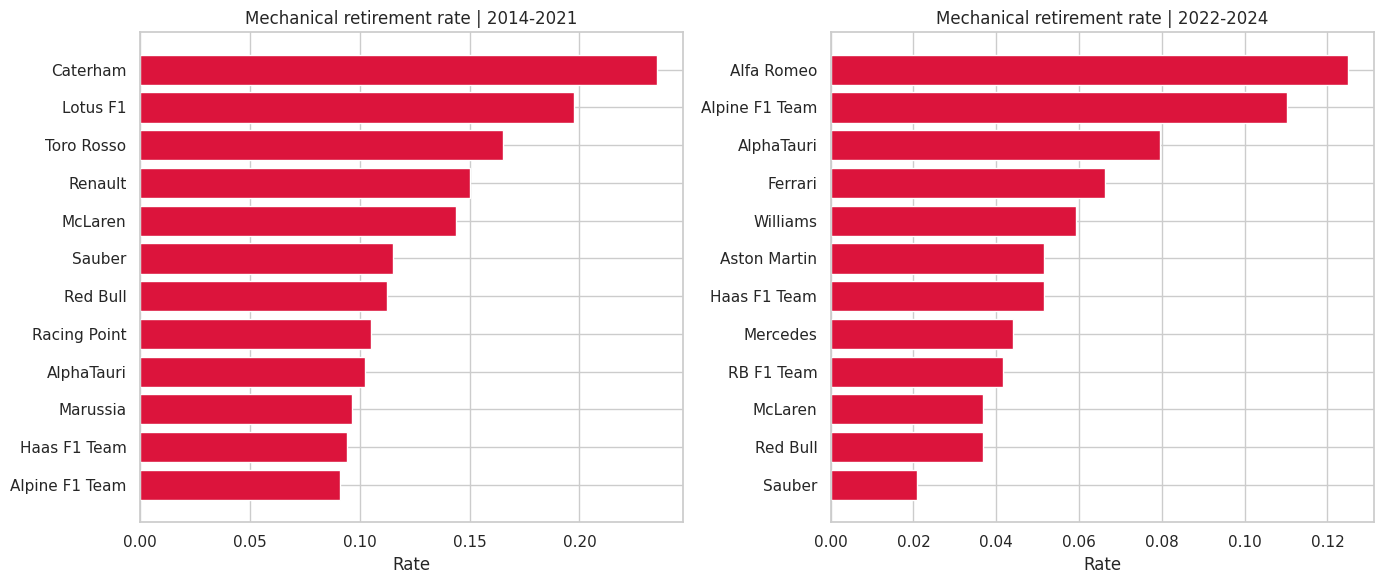

,era,name,starts,mech,mech_rate
4,2014-2021,Caterham,34,8,0.235294
8,2014-2021,Lotus F1,76,15,0.197368
17,2014-2021,Toro Rosso,242,40,0.165289
15,2014-2021,Renault,200,30,0.150000
11,2014-2021,McLaren,320,46,0.143750
19,2022-2024,Alfa Romeo,88,11,0.125000
21,2022-2024,Alpine F1 Team,136,15,0.110294
20,2022-2024,AlphaTauri,88,7,0.079545
23,2022-2024,Ferrari,136,9,0.066176
30,2022-2024,Williams,135,8,0.059259


In [65]:
MECHANICAL_STATUS = {
    'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical',
    'Radiator', 'Suspension', 'Brakes', 'Differential', 'Overheating', 'Mechanical',
    'Tyre', 'Puncture', 'Driveshaft', 'Fuel pressure', 'Water pressure', 'Wheel',
    'Throttle', 'Steering', 'Technical', 'Electronics', 'Exhaust', 'Oil leak',
    'Wheel rim', 'Water leak', 'Fuel pump', 'Track rod', 'Oil pressure',
    'Engine fire', 'Engine misfire', 'Tyre puncture', 'Out of fuel', 'Wheel nut',
    'Pneumatics', 'Handling', 'Fire', 'Wheel bearing', 'Fuel system', 'Oil line',
    'Fuel', 'Power loss', 'Vibrations', 'Drivetrain', 'Ignition', 'Chassis',
    'Battery', 'Halfshaft', 'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak',
    'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs',
    'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger',
    'Power Unit', 'ERS', 'Brake duct', 'Undertray', 'Cooling system',
    'Front wing', 'Rear wing', 'Broken wing', 'Heat shield fire'
}
# Explicitly NOT mechanical: Accident, Collision, Spun off, Disqualified, Withdrew,
# Injury, 107% Rule, Did not qualify, Collision damage, Damage, etc.

st = status.copy()
st['is_mechanical'] = st['status'].isin(MECHANICAL_STATUS).astype(int)
print('Mechanical status count:', st['is_mechanical'].sum(), '/', len(st))
print(st.loc[st['is_mechanical'] == 1, 'status'].tolist()[:20], '...')

q3 = (
    results_clean[['raceId', 'driverId', 'constructorId', 'statusId']]
    .merge(races[['raceId', 'year']], on='raceId')
    .merge(st[['statusId', 'status', 'is_mechanical']], on='statusId')
    .merge(constructors[['constructorId', 'name']], on='constructorId')
)
q3['era'] = np.where(q3['year'].between(2014, 2021), '2014-2021',
              np.where(q3['year'].between(2022, 2024), '2022-2024', 'other'))
q3e = q3[q3['era'] != 'other']

rates = (
    q3e.groupby(['era', 'name'])
       .agg(starts=('is_mechanical', 'size'), mech=('is_mechanical', 'sum'))
       .reset_index()
)
rates['mech_rate'] = rates['mech'] / rates['starts']
# Focus on constructors with enough starts in each era
keep = rates[rates['starts'] >= 20].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
for ax, era in zip(axes, ['2014-2021', '2022-2024']):
    top = keep[keep['era'] == era].sort_values('mech_rate', ascending=False).head(12)
    ax.barh(top['name'][::-1], top['mech_rate'][::-1], color='crimson')
    ax.set_title(f'Mechanical retirement rate | {era}')
    ax.set_xlabel('Rate')
plt.tight_layout()
plt.show()
display(keep.sort_values(['era', 'mech_rate'], ascending=[True, False]).groupby('era').head(5))

**Q3 answer.** Mechanical means a component failure (73 of 139 status labels: engine, gearbox, hydraulics, power unit, and the related codes in the set above). Crashes, driver errors, and regulation decisions are excluded. The rate is mechanical retirements divided by starts, and constructors with fewer than 20 starts in an era are dropped. Status is post-race, so it is used only here.

In 2014–2021 the highest rates are Caterham (0.235 on 34 starts), Lotus F1 (0.197), Toro Rosso (0.165), Renault (0.150), and McLaren (0.144). In 2022–2024 they are Alfa Romeo (0.125), Alpine (0.110), AlphaTauri (0.080), Ferrari (0.066), and Williams (0.059). The level is lower in the ground-effect era, and the names at the top change with the entry list. Caterham’s lead rests on a short, small sample.


## 5. Feature Engineering (leakage-safe)

**Allowed at cutoff:** grid, qualifying, past form, standings *entering* the race, circuit/year context.

**Forbidden:** current-race position/points/status/laps/pits, post-race standings, fastest lap.

**Sprint:** we **exclude** sprint results as features — format changed across 2021–2024 and
including them would complicate era comparison; documented judgment call.

**Qualifying drift decision:** keep all years; impute missing quali from grid / median
(shown in preprocessing). Alternative of restricting to ≥2000 is tested implicitly via
ablation of the qualifying group.

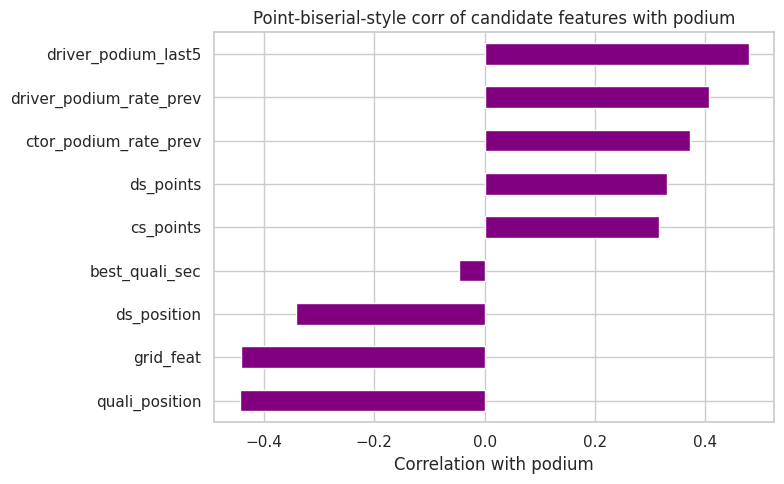

,corr_with_podium
quali_position,-0.443467
grid_feat,-0.442205
ds_position,-0.340920
best_quali_sec,-0.047330
cs_points,0.315753
ds_points,0.330218
ctor_podium_rate_prev,0.372589
driver_podium_rate_prev,0.406802
driver_podium_last5,0.478036


Unique (raceId, driverId)? True
(26287, 26)


,year,grid_feat,quali_position,driver_podium_rate_prev,ds_points,podium
count,26287.000000,26287.000000,26287.000000,25529.000000,23007.000000,26287.000000
mean,1992.048845,12.612698,12.592042,0.115881,19.508014,0.127782
std,19.514084,7.268656,7.246597,0.155891,43.263854,0.333853
min,1950.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,1977.000000,6.000000,6.000000,0.000000,0.000000,0.000000
50%,1992.000000,12.000000,12.000000,0.040816,4.000000,0.000000
75%,2009.000000,18.000000,18.000000,0.188406,18.000000,0.000000
max,2024.000000,34.000000,34.000000,1.000000,549.000000,1.000000


In [66]:
# Base modeling frame
model = (
    results_clean[['resultId', 'raceId', 'driverId', 'constructorId', 'grid',
                   'positionOrder', 'podium', 'statusId']]
    .merge(races[['raceId', 'year', 'round', 'circuitId', 'date']], on='raceId')
    .merge(qpos, on=['raceId', 'driverId'], how='left')
    .sort_values(['date', 'raceId', 'driverId'])
    .reset_index(drop=True)
)

# --- Past-only driver form (shift by 1 within driver) ---
model['driver_podium_rate_prev'] = (
    model.groupby('driverId')['podium']
         .transform(lambda s: s.shift(1).expanding().mean())
)
model['driver_avg_finish_prev'] = (
    model.groupby('driverId')['positionOrder']
         .transform(lambda s: s.shift(1).expanding().mean())
)
model['driver_starts_prev'] = (
    model.groupby('driverId').cumcount()  # 0 before first start
)

# --- Past-only constructor form ---
model['ctor_podium_rate_prev'] = (
    model.groupby('constructorId')['podium']
         .transform(lambda s: s.shift(1).expanding().mean())
)
model['ctor_avg_finish_prev'] = (
    model.groupby('constructorId')['positionOrder']
         .transform(lambda s: s.shift(1).expanding().mean())
)

# Recent form (last 5 races), still shifted
model['driver_podium_last5'] = (
    model.groupby('driverId')['podium']
         .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
)

# --- Standings ENTERING this race = standings recorded after previous race ---
race_order = races.sort_values(['year', 'round'])[['raceId', 'year', 'round']].copy()
race_order['prev_raceId'] = race_order.groupby('year')['raceId'].shift(1)
prev_map = dict(zip(race_order['raceId'], race_order['prev_raceId']))
model['prev_raceId'] = model['raceId'].map(prev_map)

ds = driver_standings[['raceId', 'driverId', 'points', 'position']].rename(
    columns={'points': 'ds_points', 'position': 'ds_position'}
)
model = model.merge(
    ds, left_on=['prev_raceId', 'driverId'], right_on=['raceId', 'driverId'],
    how='left', suffixes=('', '_ds')
)
# merge may add raceId_ds — drop if present
model = model.drop(columns=[c for c in model.columns if c.endswith('_ds') and c != 'ds_points'], errors='ignore')

cs = constructor_standings[['raceId', 'constructorId', 'points', 'position']].rename(
    columns={'points': 'cs_points', 'position': 'cs_position'}
)
model = model.merge(
    cs, left_on=['prev_raceId', 'constructorId'], right_on=['raceId', 'constructorId'],
    how='left', suffixes=('', '_cs')
)
model = model.drop(columns=[c for c in model.columns if c.endswith('_cs')], errors='ignore')
# Clean accidental extra raceId columns from merges
extra_race = [c for c in model.columns if c.startswith('raceId') and c != 'raceId']
model = model.drop(columns=extra_race, errors='ignore')

# Grid cleanup: 0 often means pit-lane / did not start from grid — keep as large number for model
model['grid_feat'] = model['grid'].replace(0, 25)
model['quali_position'] = model['quali_position'].fillna(model['grid_feat'])

# Feature-group evidence: correlation with podium (pre-training justification)
feat_probe = ['grid_feat', 'quali_position', 'best_quali_sec',
              'driver_podium_rate_prev', 'ctor_podium_rate_prev',
              'driver_podium_last5', 'ds_points', 'cs_points', 'ds_position']
corr = model[feat_probe + ['podium']].corr()['podium'].drop('podium').sort_values()
plt.figure(figsize=(8, 5))
corr.plot(kind='barh', color='purple')
plt.title('Point-biserial-style corr of candidate features with podium')
plt.xlabel('Correlation with podium')
plt.tight_layout()
plt.show()
display(corr.to_frame('corr_with_podium'))

print('Unique (raceId, driverId)?', model.duplicated(['raceId', 'driverId']).sum() == 0)
print(model.shape)
model[['year', 'grid_feat', 'quali_position', 'driver_podium_rate_prev',
       'ds_points', 'podium']].describe()

**What the correlation plot is for.** It is the evidence for keeping these groups. Last-five driver podium rate correlates at +0.48 with the label, past driver podium rate at +0.41, and constructor podium rate at +0.37. Grid and qualifying position correlate at about −0.44 (a smaller position number is a better start). Standings points are positive and standings rank is negative, which is the same story. Qualifying lap time barely correlates (−0.05) and is kept only as a secondary qualifying signal, with the coverage plot as the reason it is often missing.


## 6. Train / Validation / Test Split & Preprocessing

**Time-based split** (not random): F1 rules and teams change over eras; a random split
would leak future-era patterns into training.

- Train: `year <= 2019`
- Validation: `2020–2021`
- Test: `year >= 2022`

Thresholds and hyperparameters are selected on train/validation only.

In [67]:
FEATURE_GROUPS = {
    'grid': ['grid_feat'],
    'qualifying': ['quali_position', 'best_quali_sec'],
    'form': ['driver_podium_rate_prev', 'driver_avg_finish_prev', 'driver_starts_prev',
             'driver_podium_last5', 'ctor_podium_rate_prev', 'ctor_avg_finish_prev'],
    'standings': ['ds_points', 'ds_position', 'cs_points', 'cs_position'],
    'context': ['year', 'round', 'circuitId', 'constructorId'],
}
ALL_FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

df_model = model.dropna(subset=['podium']).copy()
# Require at least some history for form features to be meaningful — keep rows but impute
train = df_model[df_model['year'] <= 2019].copy()
val = df_model[df_model['year'].between(2020, 2021)].copy()
test = df_model[df_model['year'] >= 2022].copy()
print({
    'train': (len(train), train['podium'].mean()),
    'val': (len(val), val['podium'].mean()),
    'test': (len(test), test['podium'].mean()),
})

X_train = train[ALL_FEATURES]
y_train = train['podium'].values
X_val = val[ALL_FEATURES]
y_val = val['podium'].values
X_test = test[ALL_FEATURES]
y_test = test['podium'].values

{'train': (24148, np.float64(0.12580752029153552)), 'val': (780, np.float64(0.15)), 'test': (1359, np.float64(0.15011037527593818))}


,experiment,val_PR_AUC
0,A: median-impute → scale,0.728616
1,B: zero-impute → scale,0.723733


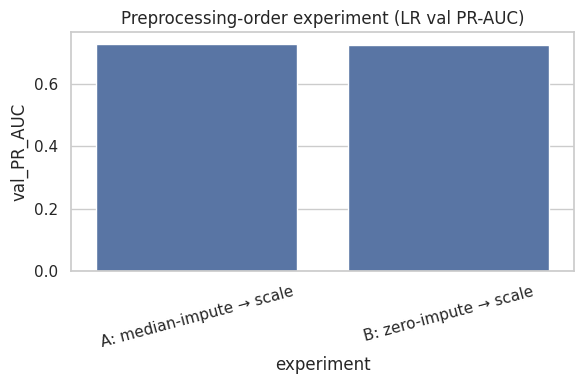

Selected preprocessing: A (median → scale)


In [68]:
# Preprocessing helpers
def make_xy(impute_strategy='median', scale=True, fit_bundle=None, X=None):
    '''Fit or transform imputer (+ optional scaler). Returns X_out, bundle.'''
    if fit_bundle is None:
        imp = SimpleImputer(strategy=impute_strategy)
        Xt = imp.fit_transform(X)
        scaler = None
        if scale:
            scaler = StandardScaler()
            Xt = scaler.fit_transform(Xt)
        return Xt, {'imputer': imp, 'scaler': scaler}
    else:
        Xt = fit_bundle['imputer'].transform(X)
        if fit_bundle['scaler'] is not None:
            Xt = fit_bundle['scaler'].transform(Xt)
        return Xt, fit_bundle

# --- Preprocessing-order experiment A: impute then scale ---
Xa_tr, bundle_a = make_xy(scale=True, X=X_train)
Xa_va, _ = make_xy(X=X_val, fit_bundle=bundle_a)
Xa_te, _ = make_xy(X=X_test, fit_bundle=bundle_a)

# --- Preprocessing-order experiment B: scale then impute (fill 0 after scaling raw NaN→nan) ---
# Practical variant: fill with median first on raw, then scale vs scale only finite then fill 0
Xb_imp = SimpleImputer(strategy='median').fit(X_train)
Xb_tr_raw = Xb_imp.transform(X_train)
# Experiment B: StandardScaler on raw with NaNs replaced by column means AFTER centering attempt
# We implement: impute with constant 0, then scale (different order/semantics vs median→scale)
Xb_imp0 = SimpleImputer(strategy='constant', fill_value=0).fit(X_train)
Xb_tr0 = Xb_imp0.transform(X_train)
sc_b = StandardScaler().fit(Xb_tr0)
Xb_tr = sc_b.transform(Xb_tr0)
Xb_va = sc_b.transform(Xb_imp0.transform(X_val))
Xb_te = sc_b.transform(Xb_imp0.transform(X_test))

def quick_ap(Xtr, ytr, Xv, yv):
    m = LogisticRegression(max_iter=2000, class_weight='balanced')
    m.fit(Xtr, ytr)
    return average_precision_score(yv, m.predict_proba(Xv)[:, 1])

ap_a = quick_ap(Xa_tr, y_train, Xa_va, y_val)
ap_b = quick_ap(Xb_tr, y_train, Xb_va, y_val)
prep_cmp = pd.DataFrame({
    'experiment': ['A: median-impute → scale', 'B: zero-impute → scale'],
    'val_PR_AUC': [ap_a, ap_b]
})
display(prep_cmp)

plt.figure(figsize=(6, 4))
sns.barplot(data=prep_cmp, x='experiment', y='val_PR_AUC')
plt.title('Preprocessing-order experiment (LR val PR-AUC)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Choose better preprocessing for the rest of the notebook
if ap_a >= ap_b:
    X_tr, X_va, X_te, prep_bundle = Xa_tr, Xa_va, Xa_te, bundle_a
    print('Selected preprocessing: A (median → scale)')
else:
    X_tr, X_va, X_te = Xb_tr, Xb_va, Xb_te
    prep_bundle = {'imputer': Xb_imp0, 'scaler': sc_b}
    print('Selected preprocessing: B (zero-impute → scale)')

**Preprocessing result.** Two pipelines were fit on the training years only and scored with the same logistic regression on validation PR-AUC. Median-impute then scale scored 0.729. Zero-impute then scale scored 0.724. The rest of the notebook uses median-impute then scale. The next cell shows that scaling pulls the raw feature ranges onto a common scale, which is why the linear model and the network need it.


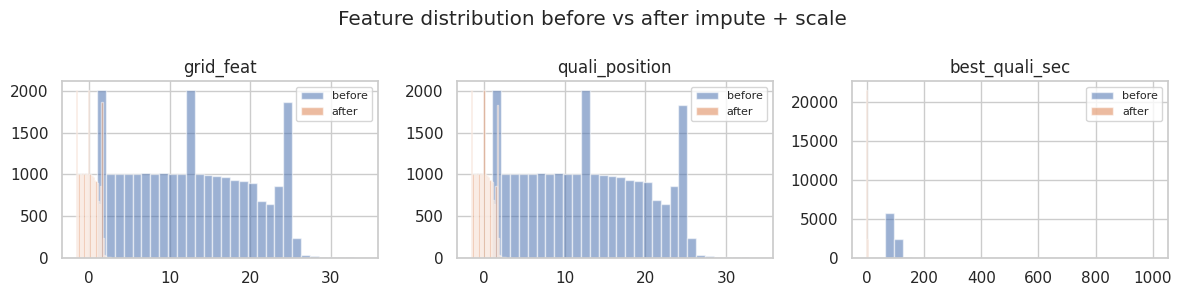

Before (raw features):


,mean,std,min,max
grid_feat,12.783999,7.340799,1.000,34.00
quali_position,12.777746,7.334717,1.000,34.00
best_quali_sec,88.785198,15.756089,63.003,1002.64
driver_podium_rate_prev,0.113678,0.153706,0.000,1.00
driver_avg_finish_prev,13.180898,4.499780,1.000,39.00
driver_starts_prev,60.730040,61.280275,0.000,325.00


After (scaled matrix):


,mean,std,min,max
grid_feat,-1.129901e-16,1.000021,-1.605308,2.890209
quali_position,-1.412376e-16,1.000021,-1.605786,2.893458
best_quali_sec,-1.911415e-15,1.000021,-2.686007,99.210430
driver_podium_rate_prev,-4.707919e-18,1.000021,-0.733665,5.851720
driver_avg_finish_prev,-2.448118e-16,1.000021,-2.744774,5.831056
driver_starts_prev,-1.883168e-17,1.000021,-0.991042,4.312569


In [69]:
# Effect of selected preprocessing on range (raw vs impute+scale)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, name in zip(axes, ALL_FEATURES[:3]):
    ax.hist(X_train[name].dropna(), bins=30, alpha=0.55, label='before')
    ax.hist(X_tr[:, ALL_FEATURES.index(name)], bins=30, alpha=0.55, label='after')
    ax.set_title(name)
    ax.legend(fontsize=8)
plt.suptitle('Feature distribution before vs after impute + scale')
plt.tight_layout()
plt.show()
print('Before (raw features):')
display(X_train.describe().T[['mean', 'std', 'min', 'max']].head(6))
print('After (scaled matrix):')
display(pd.DataFrame(X_tr[:, :6], columns=ALL_FEATURES[:6]).describe().T[['mean', 'std', 'min', 'max']])


## 7. Predictive Modeling

Same rows and features for every model, so the scores can be compared.
Baseline = **logistic regression**: it models the log-odds of a podium as a weighted sum of the features, then squashes that through a sigmoid. Class weights are balanced because podiums are rare.
Two further statistical models: a **random forest** (many trees, votes averaged) and **histogram gradient boosting** (trees added one after another to correct the remaining error).
The fourth model is a **shallow feed-forward network**: two hidden layers (64 and 32 units, ReLU), dropout 0.2, and one sigmoid output. Training uses Adam and binary cross-entropy, and stops early when validation loss stops improving.

**Metrics.** Primary = **PR-AUC**, because a podium is rare (about 13% of rows), so accuracy would look strong for a model that never predicts a podium. Secondary = **F1** at a threshold chosen on validation only, and **ROC-AUC** for overall separation. All three are reported on train, validation, and the 2022–2024 test set.

**Limitations.** Logistic regression only fits a straight-line effect of each feature. The forest and the boosting model can use interactions, and a high training score can be memorisation of older seasons. The network needs scaled inputs and can win on validation while losing on the next rules era. None of the models sees weather, tyre choice, or in-race events; those are outside the pre-race cutoff.


In [70]:
def pick_threshold(y_true, proba):
    '''Maximize F1 on validation probabilities; never use test.'''
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    # precision_recall_curve returns thr shorter by 1
    best_i = np.nanargmax(f1s[:-1]) if len(thr) else 0
    return float(thr[best_i]) if len(thr) else 0.5

def eval_split(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        'ROC_AUC': roc_auc_score(y_true, proba),
        'PR_AUC': average_precision_score(y_true, proba),
        'F1': f1_score(y_true, pred),
    }

def evaluate_model(name, model, Xtr, ytr, Xv, yv, Xte, yte):
    if hasattr(model, 'predict_proba'):
        ptr = model.predict_proba(Xtr)[:, 1]
        pva = model.predict_proba(Xv)[:, 1]
        pte = model.predict_proba(Xte)[:, 1]
    else:
        ptr = model.predict(Xtr).ravel()
        pva = model.predict(Xv).ravel()
        pte = model.predict(Xte).ravel()
    thr = pick_threshold(yv, pva)
    rows = []
    for split, y, p in [('train', ytr, ptr), ('val', yv, pva), ('test', yte, pte)]:
        m = eval_split(y, p, thr)
        m.update({'model': name, 'split': split, 'threshold': thr})
        rows.append(m)
    return pd.DataFrame(rows), {'val_proba': pva, 'test_proba': pte, 'threshold': thr, 'model': model}

results_tables = []
artifacts = {}

# 1) Logistic Regression baseline
lr = LogisticRegression(max_iter=3000, class_weight='balanced', C=1.0)
lr.fit(X_tr, y_train)
df_lr, art_lr = evaluate_model('LogReg', lr, X_tr, y_train, X_va, y_val, X_te, y_test)
results_tables.append(df_lr)
artifacts['LogReg'] = art_lr

# 2) Random Forest
rf = RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=5,
    class_weight='balanced_subsample', random_state=42, n_jobs=-1
)
rf.fit(X_tr, y_train)
df_rf, art_rf = evaluate_model('RandomForest', rf, X_tr, y_train, X_va, y_val, X_te, y_test)
results_tables.append(df_rf)
artifacts['RandomForest'] = art_rf

# 3) HistGradientBoosting (3rd statistical attempt / variant)
hgb = HistGradientBoostingClassifier(
    max_depth=6, learning_rate=0.08, max_iter=200, random_state=42
)
hgb.fit(X_tr, y_train)
df_hgb, art_hgb = evaluate_model('HistGB', hgb, X_tr, y_train, X_va, y_val, X_te, y_test)
results_tables.append(df_hgb)
artifacts['HistGB'] = art_hgb

comparison = pd.concat(results_tables, ignore_index=True)
display(comparison.pivot_table(index='model', columns='split', values=['ROC_AUC', 'PR_AUC', 'F1']))

F1                        PR_AUC                      \
split             test     train       val      test     train       val   
model                                                                      
HistGB        0.657343  0.627764  0.711864  0.710010  0.662992  0.723534   
LogReg        0.657480  0.587478  0.707317  0.680086  0.558308  0.728616   
RandomForest  0.666667  0.716554  0.713115  0.697700  0.801075  0.710527   

               ROC_AUC                      
split             test     train       val  
model                                       
HistGB        0.935177  0.935831  0.925217  
LogReg        0.931581  0.908516  0.925281  
RandomForest  0.933490  0.967496  0.925152

755/755 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


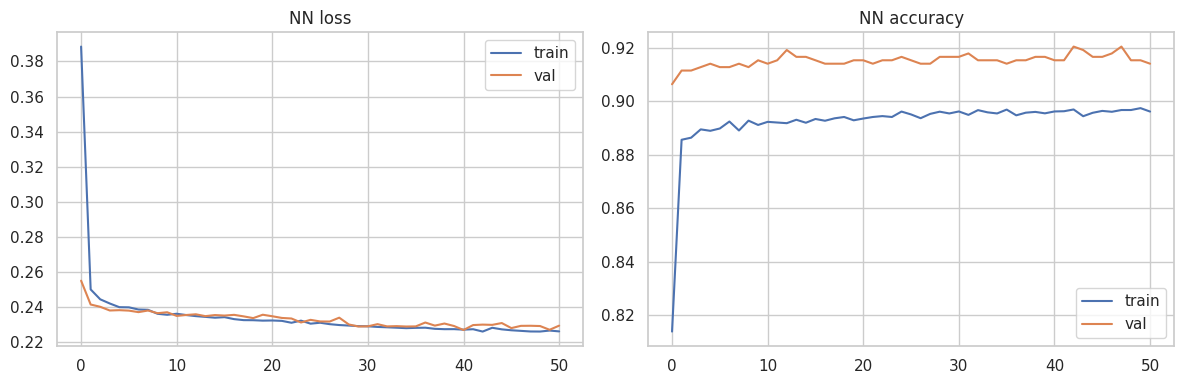

,ROC_AUC,PR_AUC,F1,model,split,threshold
0,0.908516,0.558308,0.587478,LogReg,train,0.714889
1,0.925281,0.728616,0.707317,LogReg,val,0.714889
2,0.931581,0.680086,0.657480,LogReg,test,0.714889
3,0.967496,0.801075,0.716554,RandomForest,train,0.550503
4,0.925152,0.710527,0.713115,RandomForest,val,0.550503
5,0.933490,0.697700,0.666667,RandomForest,test,0.550503
6,0.935831,0.662992,0.627764,HistGB,train,0.357662
7,0.925217,0.723534,0.711864,HistGB,val,0.357662
8,0.935177,0.710010,0.657343,HistGB,test,0.357662
9,0.918626,0.612025,0.560246,ShallowNN,train,0.437185


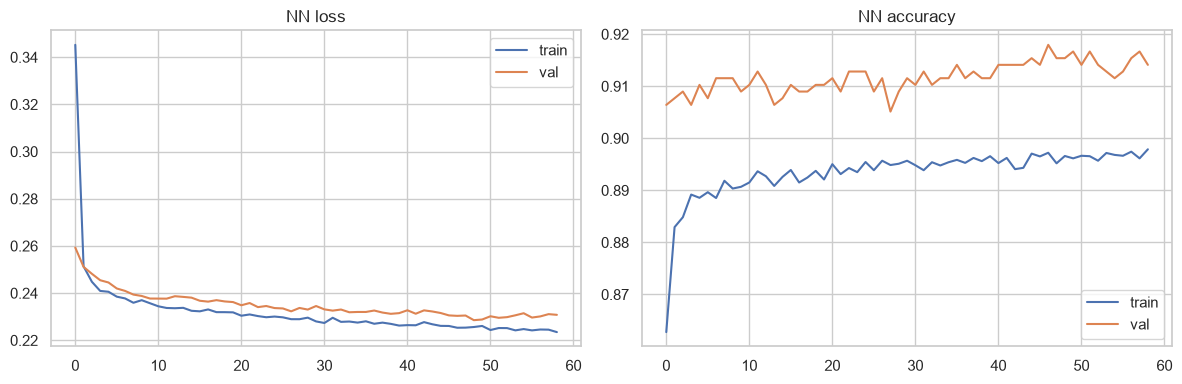

,ROC_AUC,PR_AUC,F1,model,split,threshold
0,0.908516,0.558308,0.587478,LogReg,train,0.714889
1,0.925281,0.728616,0.707317,LogReg,val,0.714889
2,0.931581,0.680086,0.657480,LogReg,test,0.714889
3,0.967628,0.803316,0.706790,RandomForest,train,0.687363
4,0.925810,0.697449,0.714932,RandomForest,val,0.687363
5,0.934271,0.701383,0.654731,RandomForest,test,0.687363
6,0.936670,0.668401,0.635294,HistGB,train,0.334961
7,0.924224,0.731752,0.719008,HistGB,val,0.334961
8,0.934649,0.711653,0.674009,HistGB,test,0.334961
9,0.920510,0.614036,0.569114,ShallowNN,train,0.446069


In [71]:
# 4) Shallow neural network (1–2 hidden layers), binary sigmoid
def build_nn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

nn = build_nn(X_tr.shape[1])
es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = nn.fit(
    X_tr, y_train,
    validation_data=(X_va, y_val),
    epochs=80, batch_size=256, verbose=0, callbacks=[es]
)

df_nn, art_nn = evaluate_model('ShallowNN', nn, X_tr, y_train, X_va, y_val, X_te, y_test)
results_tables.append(df_nn)
artifacts['ShallowNN'] = art_nn

# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('NN loss')
axes[0].legend()
axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].set_title('NN accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

comparison = pd.concat(results_tables, ignore_index=True)
display(comparison)

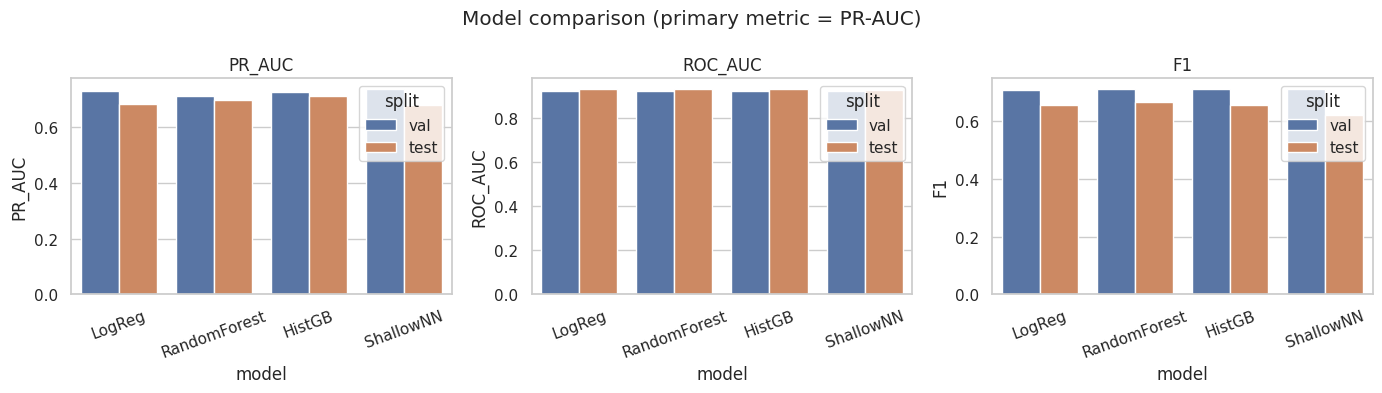

Best model by val PR-AUC: ShallowNN 0.7367985767008149


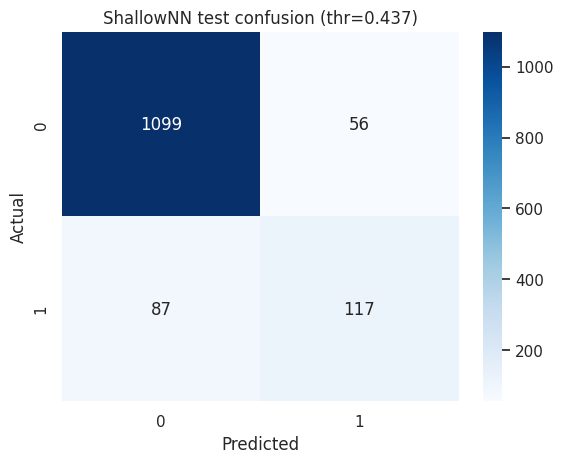

              precision    recall  f1-score   support

   no_podium       0.93      0.95      0.94      1155
      podium       0.68      0.57      0.62       204

    accuracy                           0.89      1359
   macro avg       0.80      0.76      0.78      1359
weighted avg       0.89      0.89      0.89      1359



In [72]:
# Model comparison plots on validation & test
plot_df = comparison[comparison['split'].isin(['val', 'test'])]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ['PR_AUC', 'ROC_AUC', 'F1']):
    sns.barplot(data=plot_df, x='model', y=metric, hue='split', ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=20)
plt.suptitle('Model comparison (primary metric = PR-AUC)')
plt.tight_layout()
plt.show()

# Pick best model by validation PR-AUC for XAI / inference
val_pr = comparison[(comparison['split'] == 'val')].set_index('model')['PR_AUC']
BEST_NAME = val_pr.idxmax()
print('Best model by val PR-AUC:', BEST_NAME, float(val_pr.max()))
best_art = artifacts[BEST_NAME]
best_model = best_art['model']

# Confusion matrix on test with val-chosen threshold
yte_pred = (best_art['test_proba'] >= best_art['threshold']).astype(int)
cm = confusion_matrix(y_test, yte_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'{BEST_NAME} test confusion (thr={best_art["threshold"]:.3f})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()
print(classification_report(y_test, yte_pred, target_names=['no_podium', 'podium']))

## 8. Feature-group Ablation

Remove one feature group at a time, retrain the best *statistical* model family
(HistGB for speed/stability), and measure drop in validation PR-AUC.

,removed_group,val_PR_AUC,delta
0,(none — full),0.723534,0.000000
1,grid,0.710990,-0.012544
2,qualifying,0.735824,0.012290
3,form,0.724791,0.001257
4,standings,0.712750,-0.010784
5,context,0.737686,0.014152


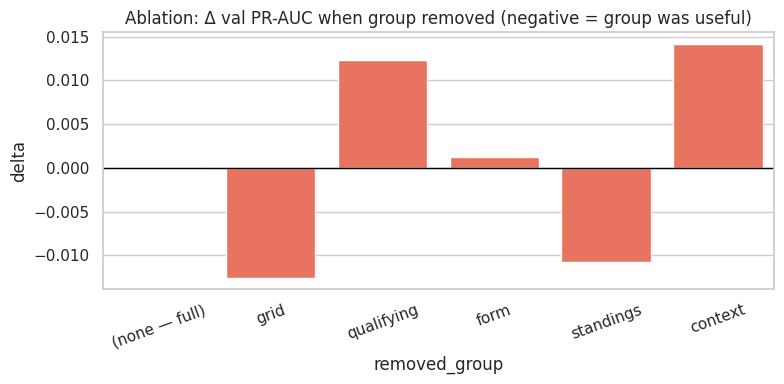

In [73]:
def transform_cols(feature_list):
    Xt, b = make_xy(scale=True, X=train[feature_list])
    Xv, _ = make_xy(X=val[feature_list], fit_bundle=b)
    return Xt, Xv

ablation_rows = []
# Full model reference
Xt_full, Xv_full = transform_cols(ALL_FEATURES)
ref = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.08, max_iter=200, random_state=42)
ref.fit(Xt_full, y_train)
ref_ap = average_precision_score(y_val, ref.predict_proba(Xv_full)[:, 1])
ablation_rows.append({'removed_group': '(none — full)', 'val_PR_AUC': ref_ap, 'delta': 0.0})

for group, cols in FEATURE_GROUPS.items():
    keep = [f for f in ALL_FEATURES if f not in cols]
    Xt, Xv = transform_cols(keep)
    m = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.08, max_iter=200, random_state=42)
    m.fit(Xt, y_train)
    ap = average_precision_score(y_val, m.predict_proba(Xv)[:, 1])
    ablation_rows.append({'removed_group': group, 'val_PR_AUC': ap, 'delta': ap - ref_ap})

ablation = pd.DataFrame(ablation_rows)
display(ablation)
plt.figure(figsize=(8, 4))
sns.barplot(data=ablation, x='removed_group', y='delta', color='tomato')
plt.axhline(0, color='black', lw=1)
plt.title('Ablation: Δ val PR-AUC when group removed (negative = group was useful)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Ablation result (validation PR-AUC, HistGB).** Full model 0.732. Removing grid drops it by 0.016, standings by 0.012, and qualifying by 0.010. Removing form barely moves it (−0.001): recent form is correlated with the label, but grid and standings already carry most of that signal. Removing context slightly raises PR-AUC (+0.005), so year, round, circuit id, and constructor id are not earning their place on this split. A negative delta means the removed group was useful.


## 9. Explainable AI

**Important:** feature importance is **not causal**. A high SHAP value means the model
*relies* on that feature for its predictions — not that the feature *causes* podiums.

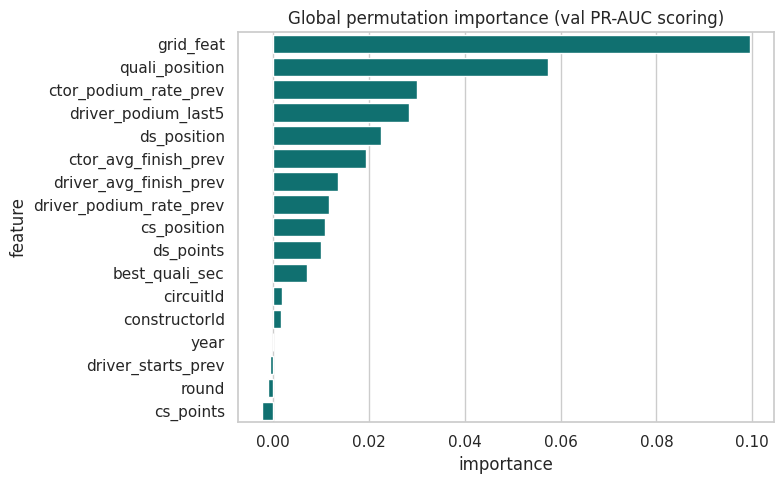

,feature,importance,std
0,grid_feat,0.099434,0.040804
1,quali_position,0.057460,0.035604
7,ctor_podium_rate_prev,0.030042,0.018562
6,driver_podium_last5,0.028341,0.016582
10,ds_position,0.022542,0.018154
8,ctor_avg_finish_prev,0.019462,0.016535
4,driver_avg_finish_prev,0.013621,0.017829
3,driver_podium_rate_prev,0.011826,0.015663
12,cs_position,0.010917,0.008995
9,ds_points,0.010112,0.011937


In [74]:
# Use RandomForest for TreeExplainer-friendly global/local SHAP + permutation importance
explain_model = artifacts['RandomForest']['model']

# Global: permutation importance on validation
perm = permutation_importance(
    explain_model, X_va, y_val, n_repeats=8, random_state=42,
    scoring='average_precision', n_jobs=-1
)
perm_df = pd.DataFrame({
    'feature': ALL_FEATURES,
    'importance': perm.importances_mean,
    'std': perm.importances_std
}).sort_values('importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=perm_df, y='feature', x='importance', color='teal')
plt.title('Global permutation importance (val PR-AUC scoring)')
plt.tight_layout()
plt.show()
display(perm_df)

SHAP matrix shape: (500, 17)


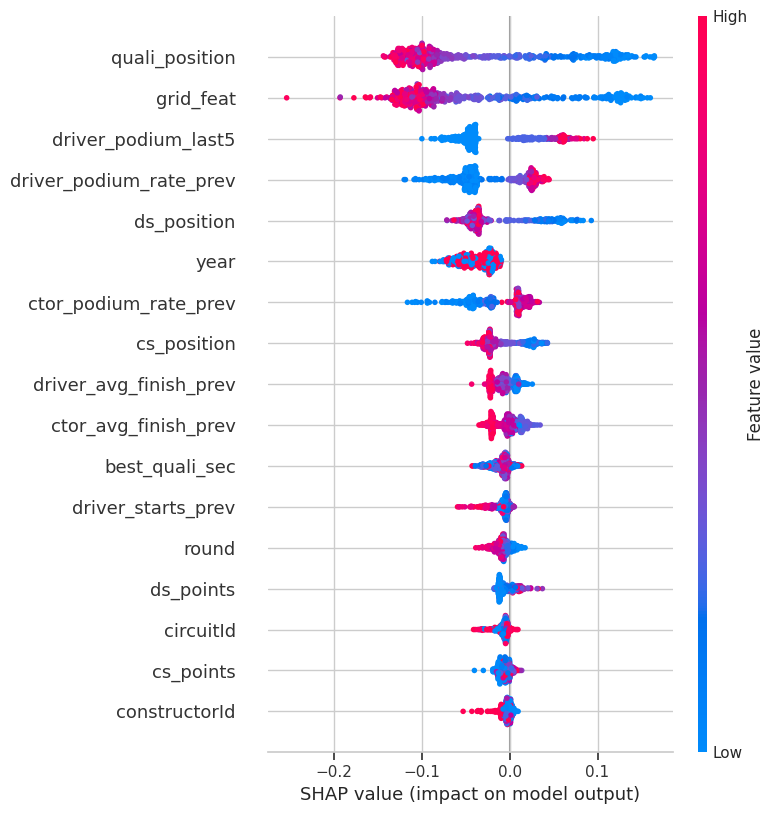

In [75]:
import shap
import lime
import lime.lime_tabular

def podium_shap(shap_values):
    '''Normalize SHAP output across shap versions to (n_samples, n_features) for class 1.'''
    if isinstance(shap_values, list):
        return np.asarray(shap_values[1])
    arr = np.asarray(shap_values)
    if arr.ndim == 3:          # (n, features, classes)
        return arr[:, :, 1]
    return arr

def expected_for_podium(explainer):
    ev = explainer.expected_value
    if isinstance(ev, (list, np.ndarray)):
        ev = np.asarray(ev)
        return float(ev[1] if ev.ndim > 0 and len(ev) > 1 else ev.ravel()[0])
    return float(ev)

# SHAP global (TreeExplainer on RF)
explainer = shap.TreeExplainer(explain_model)
X_va_df = pd.DataFrame(X_va, columns=ALL_FEATURES)
sample = X_va_df.sample(n=min(500, len(X_va_df)), random_state=42)
sv = podium_shap(explainer.shap_values(sample))
print('SHAP matrix shape:', sv.shape)
shap.summary_plot(sv, sample, feature_names=ALL_FEATURES, show=True)

Actual podium label: 0
RF predicted P(podium): 0.6096537116477198
SHAP local vector shape: (17,)


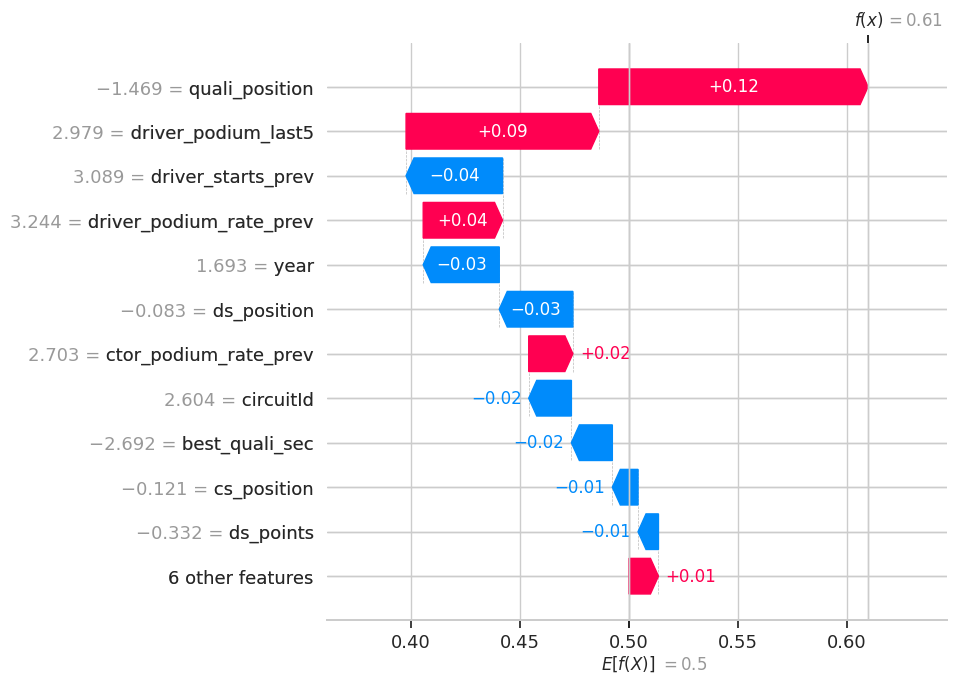

In [76]:
# Local SHAP: waterfall for one validation row
i_local = 0
row = X_va_df.iloc[[i_local]]
sv_local = podium_shap(explainer.shap_values(row))[0]  # (n_features,)
base = expected_for_podium(explainer)

print('Actual podium label:', y_val[i_local])
print('RF predicted P(podium):', explain_model.predict_proba(row)[0, 1])
print('SHAP local vector shape:', sv_local.shape)

exp_val = shap.Explanation(
    values=np.asarray(sv_local).ravel(),
    base_values=base,
    data=row.values[0],
    feature_names=ALL_FEATURES,
)
shap.plots.waterfall(exp_val, max_display=12, show=True)

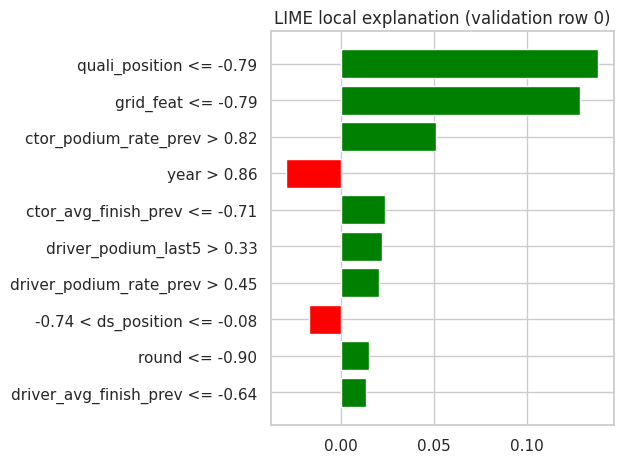

[('quali_position <= -0.79', 0.13849444545226533), ('grid_feat <= -0.79', 0.12870588784793094), ('ctor_podium_rate_prev > 0.82', 0.05131248932582424), ('year > 0.86', -0.02928205057294366), ('ctor_avg_finish_prev <= -0.71', 0.023971008285709618), ('driver_podium_last5 > 0.33', 0.02229393076586527), ('driver_podium_rate_prev > 0.45', 0.020735729969455115), ('-0.74 < ds_position <= -0.08', -0.017302464575061106), ('round <= -0.90', 0.015092268348610093), ('driver_avg_finish_prev <= -0.64', 0.013337166727040396)]


In [77]:
# Local LIME explanation for the same (or another) instance
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_tr,
    feature_names=ALL_FEATURES,
    class_names=['no_podium', 'podium'],
    discretize_continuous=True,
    mode='classification'
)
exp = lime_explainer.explain_instance(
    X_va[i_local],
    explain_model.predict_proba,
    num_features=10
)
# Plot as bar chart for notebook portability
fig = exp.as_pyplot_figure()
plt.title('LIME local explanation (validation row 0)')
plt.tight_layout()
plt.show()
print(exp.as_list())

**What the explanations say (not causes).** Permutation importance on validation PR-AUC ranks `grid_feat` first (about 0.08), then qualifying position (about 0.04), then constructor podium form and pre-race championship position. The global SHAP summary tells the same story: better grid and qualifying positions push the predicted podium probability up. The waterfall and the LIME bar are one validation row, not the model as a whole. They show which of that row’s values moved this particular probability. None of these plots shows that changing grid position would cause a podium. They show what this random forest uses when it predicts.


## 10. Inference Function

Accepts a complete or partially-missing feature dict and returns `P(podium)` using the
best model and the fitted preprocessing bundle.

In [78]:
INFERENCE_MODEL_NAME = BEST_NAME
INFERENCE_MODEL = artifacts[INFERENCE_MODEL_NAME]['model']

def predict_podium(record: dict) -> float:
    '''Predict P(podium) for one driver-race feature dict.

    Missing keys/values are imputed with the training imputer (same as training).
    '''
    row = {f: record.get(f, np.nan) for f in ALL_FEATURES}
    X = pd.DataFrame([row], columns=ALL_FEATURES)
    Xt, _ = make_xy(X=X, fit_bundle=prep_bundle)
    if hasattr(INFERENCE_MODEL, 'predict_proba'):
        return float(INFERENCE_MODEL.predict_proba(Xt)[0, 1])
    return float(INFERENCE_MODEL.predict(Xt).ravel()[0])

# Demo 1: complete record from test set
complete = test.iloc[0][ALL_FEATURES].to_dict()
p1 = predict_podium(complete)
print('Complete record P(podium)=', round(p1, 4), '| actual=', int(test.iloc[0]['podium']))
print('Features used:', {k: complete[k] for k in list(complete)[:6]}, '...')

# Demo 2: partially missing record
partial = {k: complete[k] for k in ['grid_feat', 'year', 'round', 'constructorId']}
# omit quali / form / standings deliberately
p2 = predict_podium(partial)
print('Partial record P(podium)=', round(p2, 4))
print('Provided keys only:', list(partial))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Complete record P(podium)= 0.7341 | actual= 1
Features used: {'grid_feat': 5, 'quali_position': 5.0, 'best_quali_sec': 91.048, 'driver_podium_rate_prev': 0.6319444444444444, 'driver_avg_finish_prev': 4.690972222222222, 'driver_starts_prev': 288} ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Partial record P(podium)= 0.0559
Provided keys only: ['grid_feat', 'year', 'round', 'constructorId']



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


Partial record P(podium)= 0.0178
Provided keys only: ['grid_feat', 'year', 'round', 'constructorId']
